<a href="https://colab.research.google.com/github/nehasingh913833-gif/Parametric-and-Non-parametric-Brain-Function-Connectivity-Approach-for-Predicting-Autism./blob/main/autism_classifier.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Environment Ready. Starting ABIDE Pipeline...
Loaded 1000 subjects. ASD (1): 488, Control (0): 512
Computing Parametric: Pearson...
Computing Parametric: Partial Correlation...
Computing Parametric: Tangent Space...
Computing Non-Parametric: Spearman...

Evaluating Connectivity: Pearson...



Evaluating Connectivity: Partial...

Evaluating Connectivity: Tangent...

Evaluating Connectivity: Spearman...


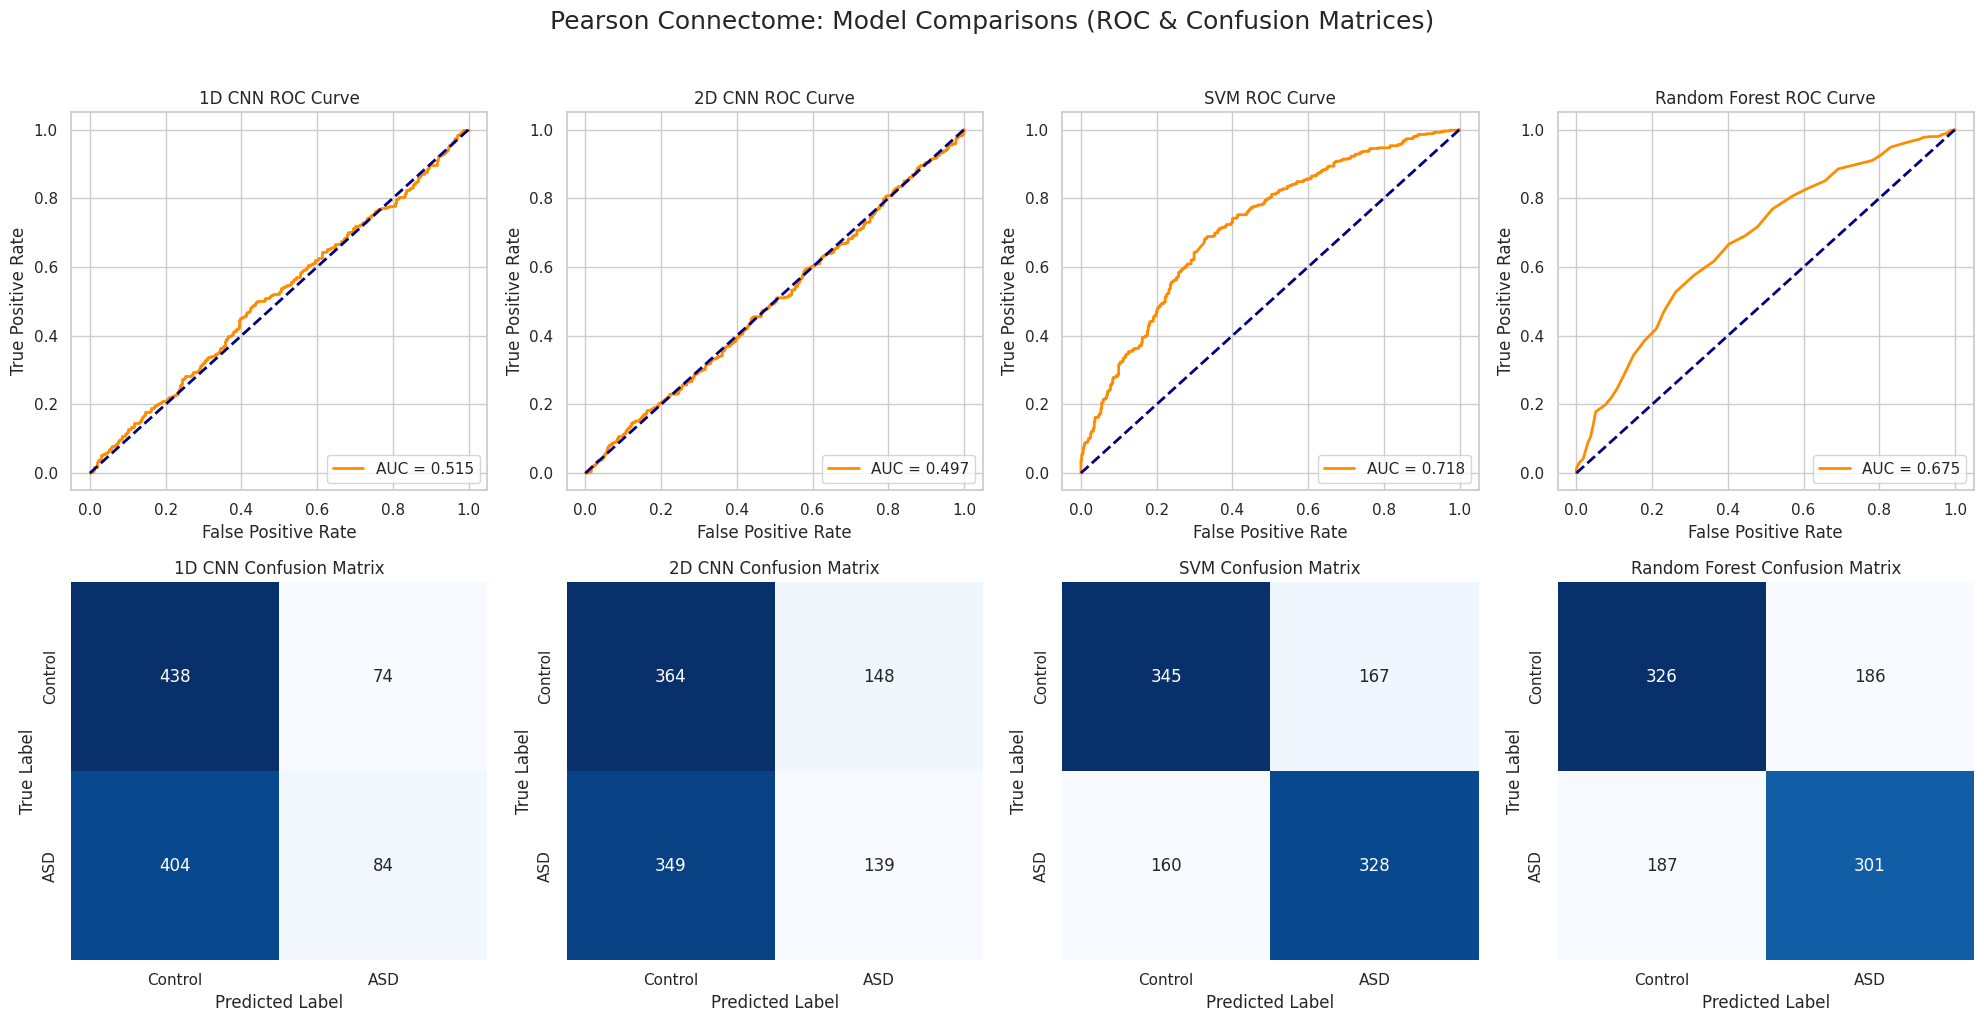


=== FINAL COMPARATIVE ANALYSIS TABLE ===


,Type,Connectome,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Parametric,Pearson,1D CNN,0.522,0.5316,0.1721,0.2601,0.5151
1,Parametric,Pearson,2D CNN,0.503,0.4843,0.2848,0.3587,0.4974
2,Parametric,Pearson,SVM,0.673,0.6626,0.6721,0.6673,0.7185
3,Parametric,Pearson,Random Forest,0.627,0.6181,0.6168,0.6174,0.6753
4,Parametric,Partial,1D CNN,0.515,0.5195,0.0820,0.1416,0.5225
5,Parametric,Partial,2D CNN,0.508,0.4900,0.2008,0.2849,0.5039
6,Parametric,Partial,SVM,0.623,0.6259,0.5656,0.5942,0.6547
7,Parametric,Partial,Random Forest,0.539,0.5328,0.4488,0.4872,0.5710
8,Parametric,Tangent,1D CNN,0.501,0.4636,0.1434,0.2191,0.5103
9,Parametric,Tangent,2D CNN,0.502,0.4900,0.5020,0.4960,0.5019


In [ ]:
# 1. INSTALL STABLE VERSIONS (Bypassing the Nilearn 0.14.0 Bug)
!pip install -q nilearn==0.13.0 scikit-learn seaborn matplotlib

import warnings
warnings.filterwarnings('ignore')
import gc

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

from nilearn.datasets import fetch_abide_pcp
from nilearn.connectome import ConnectivityMeasure
from nilearn import plotting

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, roc_curve, auc, roc_auc_score
)
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

print("Environment Ready. Starting ABIDE Pipeline...")

# ==========================================
# STEP 2: FETCH DATASET (SILENTLY) & CLEAN
# ==========================================
N_SAMPLES = 1000

print(f"Downloading {N_SAMPLES} pre-extracted ABIDE subjects (takes ~2 mins)...")
abide = fetch_abide_pcp(
    n_subjects=N_SAMPLES,
    pipeline='cpac',
    band_pass_filtering=True,
    global_signal_regression=False,
    derivatives=['rois_aal'], # Using 116 AAL ROIs to fit in Colab RAM/Disk
    quality_checked=False,
    verbose=0
)

# Extract Time Series & Labels
raw_time_series = abide.rois_aal[:N_SAMPLES]
y = (np.asarray(abide.phenotypic['DX_GROUP'])[:N_SAMPLES] == 1).astype(np.int32)

# Jitter zero-variance columns to prevent NaN matrices
time_series_list = []
rng = np.random.default_rng(42)
for ts in raw_time_series:
    ts = np.asarray(ts, dtype=np.float32)
    zero_std_cols = np.std(ts, axis=0) < 1e-8
    if np.any(zero_std_cols):
        ts[:, zero_std_cols] += rng.normal(0, 1e-5, size=(ts.shape[0], np.sum(zero_std_cols)))
    time_series_list.append(ts)

print(f"Loaded {len(time_series_list)} subjects. ASD (1): {np.sum(y==1)}, Control (0): {np.sum(y==0)}")

# ==========================================
# STEP 3: COMPUTE CONNECTIVITY MATRICES
# ==========================================
connectomes = {}

print("Computing Parametric: Pearson...")
connectomes['Pearson'] = np.nan_to_num(ConnectivityMeasure(kind='correlation').fit_transform(time_series_list), nan=0.0)

print("Computing Parametric: Partial Correlation...")
connectomes['Partial'] = np.nan_to_num(ConnectivityMeasure(kind='partial correlation').fit_transform(time_series_list), nan=0.0)

print("Computing Parametric: Tangent Space...")
connectomes['Tangent'] = np.nan_to_num(ConnectivityMeasure(kind='tangent').fit_transform(time_series_list), nan=0.0)

print("Computing Non-Parametric: Spearman...")
spearman_matrices = []
for ts in time_series_list:
    corr, _ = spearmanr(ts, axis=0)
    np.fill_diagonal(corr, 1.0)
    spearman_matrices.append(np.nan_to_num(corr, nan=0.0).astype(np.float32))
connectomes['Spearman'] = np.array(spearman_matrices)

# Clean up memory
del raw_time_series, time_series_list
gc.collect()

# ==========================================
# STEP 4: DEFINE MODELS & UNIFIED EVALUATOR
# ==========================================
def build_1d_cnn(input_shape):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv1D(16, 5, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling1D(2),
        layers.Dropout(0.3),
        layers.Conv1D(32, 3, activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.GlobalAveragePooling1D(),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

def build_2d_cnn(input_shape):
    model = models.Sequential([
        layers.Input(shape=input_shape),
        layers.Conv2D(16, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2,2)),
        layers.Dropout(0.25),
        layers.Conv2D(32, (3,3), activation='relu', padding='same'),
        layers.BatchNormalization(),
        layers.MaxPooling2D((2,2)),
        layers.Flatten(),
        layers.Dense(32, activation='relu'),
        layers.Dropout(0.4),
        layers.Dense(1, activation='sigmoid')
    ])
    model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    return model

def evaluate_model(X, y, model_name):
    """Handles CV for CNNs, SVM, and Random Forest"""
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    all_y_true, all_y_prob, all_y_pred = [], [], []

    for train_idx, val_idx in skf.split(X, y):
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        if model_name in ['1D CNN', '2D CNN']:
            builder = build_1d_cnn if model_name == '1D CNN' else build_2d_cnn
            model = builder(X.shape[1:])
            early_stop = callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True)
            model.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=20, batch_size=32, verbose=0, callbacks=[early_stop])
            y_prob = model.predict(X_val, verbose=0).ravel()
        else:
            # Flatten to 2D array for traditional ML (N, features)
            X_train_ml, X_val_ml = X_train.squeeze(-1), X_val.squeeze(-1)
            model = SVC(kernel='rbf', probability=True) if model_name == 'SVM' else RandomForestClassifier(n_estimators=100)
            model.fit(X_train_ml, y_train)
            y_prob = model.predict_proba(X_val_ml)[:, 1]

        y_pred = (y_prob >= 0.5).astype(int)
        all_y_true.extend(y_val)
        all_y_prob.extend(y_prob)
        all_y_pred.extend(y_pred)

    cm = confusion_matrix(all_y_true, all_y_pred)
    metrics = {
        'Accuracy': accuracy_score(all_y_true, all_y_pred),
        'Precision': precision_score(all_y_true, all_y_pred, zero_division=0),
        'Recall': recall_score(all_y_true, all_y_pred, zero_division=0),
        'F1-Score': f1_score(all_y_true, all_y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(all_y_true, all_y_prob)
    }
    return metrics, cm, np.array(all_y_true), np.array(all_y_prob)

# ==========================================
# STEP 5: EXECUTE PIPELINE & COLLECT RESULTS
# ==========================================
results_list = []
plot_data = {} # Save data to plot ROC/CM for the Pearson connectome

for method, matrices in connectomes.items():
    print(f"\nEvaluating Connectivity: {method}...")

    # Extract non-redundant upper triangle using NumPy (Version agnostic)
    triu_idx = np.triu_indices(matrices.shape[1], k=1)
    X_flat = StandardScaler().fit_transform(matrices[:, triu_idx[0], triu_idx[1]])[..., np.newaxis]
    X_matrix = matrices[..., np.newaxis]

    models_to_run = {
        '1D CNN': X_flat,
        '2D CNN': X_matrix,
        'SVM': X_flat,
        'Random Forest': X_flat
    }

    for model_name, X_data in models_to_run.items():
        metrics, cm, y_t, y_p = evaluate_model(X_data, y, model_name)
        results_list.append({
            'Type': 'Non-Parametric' if method == 'Spearman' else 'Parametric',
            'Connectome': method,
            'Model': model_name,
            **metrics
        })

        # Save Pearson results specifically for our visualizations below
        if method == 'Pearson':
            plot_data[model_name] = {'cm': cm, 'y_true': y_t, 'y_prob': y_p}

# ==========================================
# STEP 6: VISUALIZATIONS FOR PROJECT REPORT
# ==========================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
fig.suptitle("Pearson Connectome: Model Comparisons (ROC & Confusion Matrices)", fontsize=18, y=1.02)

for idx, model_name in enumerate(['1D CNN', '2D CNN', 'SVM', 'Random Forest']):
    data = plot_data[model_name]

    # Plot ROC Curve (Top Row)
    fpr, tpr, _ = roc_curve(data['y_true'], data['y_prob'])
    ax_roc = axes[0, idx]
    ax_roc.plot(fpr, tpr, color='darkorange', lw=2, label=f"AUC = {auc(fpr, tpr):.3f}")
    ax_roc.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
    ax_roc.set_title(f"{model_name} ROC Curve")
    ax_roc.set_xlabel("False Positive Rate")
    ax_roc.set_ylabel("True Positive Rate")
    ax_roc.legend(loc="lower right")

    # Plot Confusion Matrix (Bottom Row)
    ax_cm = axes[1, idx]
    sns.heatmap(data['cm'], annot=True, fmt='d', cmap='Blues', ax=ax_cm, cbar=False,
                xticklabels=['Control', 'ASD'], yticklabels=['Control', 'ASD'])
    ax_cm.set_title(f"{model_name} Confusion Matrix")
    ax_cm.set_xlabel("Predicted Label")
    ax_cm.set_ylabel("True Label")

plt.tight_layout()
plt.show()

print("\n=== FINAL COMPARATIVE ANALYSIS TABLE ===")
final_df = pd.DataFrame(results_list).round(4)
display(final_df)